In [1]:
import pandas as pd

df = pd.read_csv('Video_Game_Sales.csv')

print(df.head())

   Rank                      Name Platform    Year         Genre Publisher  \
0     1                Wii Sports      Wii  2006.0        Sports  Nintendo   
1     2         Super Mario Bros.      NES  1985.0      Platform  Nintendo   
2     3            Mario Kart Wii      Wii  2008.0        Racing  Nintendo   
3     4         Wii Sports Resort      Wii  2009.0        Sports  Nintendo   
4     5  Pokemon Red/Pokemon Blue       GB  1996.0  Role-Playing  Nintendo   

   NA_Sales  EU_Sales  JP_Sales  Other_Sales  Global_Sales  
0     41.49     29.02      3.77         8.46         82.74  
1     29.08      3.58      6.81         0.77         40.24  
2     15.85     12.88      3.79         3.31         35.82  
3     15.75     11.01      3.28         2.96         33.00  
4     11.27      8.89     10.22         1.00         31.37  


In [2]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  object 
 2   Platform      16598 non-null  object 
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  object 
 5   Publisher     16540 non-null  object 
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), object(4)
memory usage: 1.4+ MB
None


In [3]:
print(df.describe())

               Rank          Year      NA_Sales      EU_Sales      JP_Sales  \
count  16598.000000  16327.000000  16598.000000  16598.000000  16598.000000   
mean    8300.605254   2006.406443      0.264667      0.146652      0.077782   
std     4791.853933      5.828981      0.816683      0.505351      0.309291   
min        1.000000   1980.000000      0.000000      0.000000      0.000000   
25%     4151.250000   2003.000000      0.000000      0.000000      0.000000   
50%     8300.500000   2007.000000      0.080000      0.020000      0.000000   
75%    12449.750000   2010.000000      0.240000      0.110000      0.040000   
max    16600.000000   2020.000000     41.490000     29.020000     10.220000   

        Other_Sales  Global_Sales  
count  16598.000000  16598.000000  
mean       0.048063      0.537441  
std        0.188588      1.555028  
min        0.000000      0.010000  
25%        0.000000      0.060000  
50%        0.010000      0.170000  
75%        0.040000      0.470000  


In [4]:
columns = df.columns.tolist()
print("Стовпці DataFrame:")
for column in columns:
    print(f"- {column}")

Стовпці DataFrame:
- Rank
- Name
- Platform
- Year
- Genre
- Publisher
- NA_Sales
- EU_Sales
- JP_Sales
- Other_Sales
- Global_Sales


In [5]:
print(df.dtypes)

Rank              int64
Name             object
Platform         object
Year            float64
Genre            object
Publisher        object
NA_Sales        float64
EU_Sales        float64
JP_Sales        float64
Other_Sales     float64
Global_Sales    float64
dtype: object


In [6]:
df['Year'] = pd.to_numeric(df['Year'], errors='coerce')
print(df.dtypes)

Rank              int64
Name             object
Platform         object
Year            float64
Genre            object
Publisher        object
NA_Sales        float64
EU_Sales        float64
JP_Sales        float64
Other_Sales     float64
Global_Sales    float64
dtype: object


In [7]:
missing_columns = df.isnull().sum()
print("Пропущені значення у стовпцях:")
print(missing_columns)

Пропущені значення у стовпцях:
Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64


In [8]:
missing_rows = df.isnull().sum(axis=1)
print("\nКількість пропущених значень у кожному рядку:")
print(missing_rows[missing_rows > 0])


Кількість пропущених значень у кожному рядку:
179      1
377      1
431      1
470      2
607      1
        ..
16427    1
16493    1
16494    1
16543    1
16553    1
Length: 307, dtype: int64


In [9]:
numerical_columns = ['Year', 'NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales']
for column in numerical_columns:
    if df[column].isnull().sum() > 0:
        mean_value = df[column].mean()
        df[column] = df[column].fillna(mean_value)
        print(f"Заповнено пропущені значення у стовпці '{column}' середнім значенням: {mean_value}")

Заповнено пропущені значення у стовпці 'Year' середнім значенням: 2006.4064433147546


In [10]:
categorical_columns = ['Genre', 'Publisher']
for column in categorical_columns:
    if df[column].isnull().sum() > 0:
        mode_value = df[column].mode()[0]
        df[column].fillna(mode_value)
        print(f"Заповнено пропущені значення у стовпці '{column}' найчастішим значенням: {mode_value}")

Заповнено пропущені значення у стовпці 'Publisher' найчастішим значенням: Electronic Arts


In [11]:
missing_columns = df.isnull().sum()
print("Пропущені значення у стовпцях:")
print(missing_columns)

Пропущені значення у стовпцях:
Rank             0
Name             0
Platform         0
Year             0
Genre            0
Publisher       58
NA_Sales         0
EU_Sales         0
JP_Sales         0
Other_Sales      0
Global_Sales     0
dtype: int64


In [12]:
print(f"Кількість рядків до видалення пропусків: {df.shape[0]}")

df_cleaned = df.dropna()

print(f"Кількість рядків після видалення пропусків: {df_cleaned.shape[0]}")

Кількість рядків до видалення пропусків: 16598
Кількість рядків після видалення пропусків: 16540


In [13]:
print("Типи даних до конвертації:")
print(df.dtypes)
df['Year'] = df['Year'].astype(int)
df['Genre'] = df['Genre'].astype('category')
df['Publisher'] = df['Publisher'].astype('category')
print("\nТипи даних після конвертації:")
print(df.dtypes)

Типи даних до конвертації:
Rank              int64
Name             object
Platform         object
Year            float64
Genre            object
Publisher        object
NA_Sales        float64
EU_Sales        float64
JP_Sales        float64
Other_Sales     float64
Global_Sales    float64
dtype: object

Типи даних після конвертації:
Rank               int64
Name              object
Platform          object
Year               int64
Genre           category
Publisher       category
NA_Sales         float64
EU_Sales         float64
JP_Sales         float64
Other_Sales      float64
Global_Sales     float64
dtype: object


In [14]:
print(df.head())

   Rank                      Name Platform  Year         Genre Publisher  \
0     1                Wii Sports      Wii  2006        Sports  Nintendo   
1     2         Super Mario Bros.      NES  1985      Platform  Nintendo   
2     3            Mario Kart Wii      Wii  2008        Racing  Nintendo   
3     4         Wii Sports Resort      Wii  2009        Sports  Nintendo   
4     5  Pokemon Red/Pokemon Blue       GB  1996  Role-Playing  Nintendo   

   NA_Sales  EU_Sales  JP_Sales  Other_Sales  Global_Sales  
0     41.49     29.02      3.77         8.46         82.74  
1     29.08      3.58      6.81         0.77         40.24  
2     15.85     12.88      3.79         3.31         35.82  
3     15.75     11.01      3.28         2.96         33.00  
4     11.27      8.89     10.22         1.00         31.37  


In [15]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   Rank          16598 non-null  int64   
 1   Name          16598 non-null  object  
 2   Platform      16598 non-null  object  
 3   Year          16598 non-null  int64   
 4   Genre         16598 non-null  category
 5   Publisher     16540 non-null  category
 6   NA_Sales      16598 non-null  float64 
 7   EU_Sales      16598 non-null  float64 
 8   JP_Sales      16598 non-null  float64 
 9   Other_Sales   16598 non-null  float64 
 10  Global_Sales  16598 non-null  float64 
dtypes: category(2), float64(5), int64(2), object(2)
memory usage: 1.2+ MB
None


In [16]:
stats = df.describe()
print(stats)

               Rank          Year      NA_Sales      EU_Sales      JP_Sales  \
count  16598.000000  16598.000000  16598.000000  16598.000000  16598.000000   
mean    8300.605254   2006.399807      0.264667      0.146652      0.077782   
std     4791.853933      5.781426      0.816683      0.505351      0.309291   
min        1.000000   1980.000000      0.000000      0.000000      0.000000   
25%     4151.250000   2003.000000      0.000000      0.000000      0.000000   
50%     8300.500000   2007.000000      0.080000      0.020000      0.000000   
75%    12449.750000   2010.000000      0.240000      0.110000      0.040000   
max    16600.000000   2020.000000     41.490000     29.020000     10.220000   

        Other_Sales  Global_Sales  
count  16598.000000  16598.000000  
mean       0.048063      0.537441  
std        0.188588      1.555028  
min        0.000000      0.010000  
25%        0.000000      0.060000  
50%        0.010000      0.170000  
75%        0.040000      0.470000  


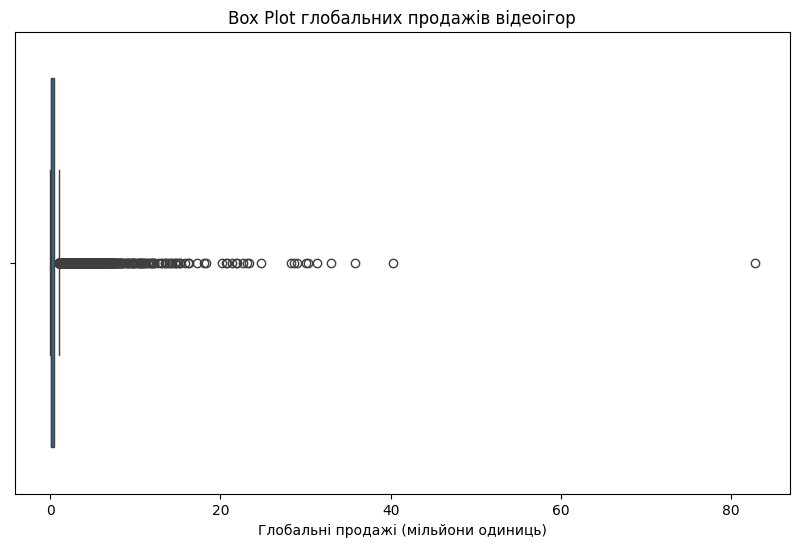

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.boxplot(x=df['Global_Sales'])
plt.title('Box Plot глобальних продажів відеоігор')
plt.xlabel('Глобальні продажі (мільйони одиниць)')
plt.show()

In [18]:
from scipy import stats

df['Z_Score_Global_Sales'] = stats.zscore(df['Global_Sales'])

anomalies = df[(df['Z_Score_Global_Sales'] > 3) | (df['Z_Score_Global_Sales'] < -3)]
print("Аномальні записи за Z-Score:")
print(anomalies)

Аномальні записи за Z-Score:
     Rank                                           Name Platform  Year  \
0       1                                     Wii Sports      Wii  2006   
1       2                              Super Mario Bros.      NES  1985   
2       3                                 Mario Kart Wii      Wii  2008   
3       4                              Wii Sports Resort      Wii  2009   
4       5                       Pokemon Red/Pokemon Blue       GB  1996   
..    ...                                            ...      ...   ...   
176   177                            Assassin's Creed II     X360  2009   
177   178       Professor Layton and the Curious Village       DS  2007   
178   179                                 Tomb Raider II       PS  1997   
179   180                                Madden NFL 2004      PS2  2006   
180   181  Dragon Quest VIII: Journey of the Cursed King      PS2  2004   

            Genre          Publisher  NA_Sales  EU_Sales  JP_Sales  \


In [19]:
df_cleaned = df[(df['Z_Score_Global_Sales'] <= 3) & (df['Z_Score_Global_Sales'] >= -3)]

df_cleaned = df_cleaned.drop(columns=['Z_Score_Global_Sales'])

print(f"Кількість рядків після видалення аномалій: {df_cleaned.shape[0]}")

Кількість рядків після видалення аномалій: 16417


In [20]:
df_cleaned.loc[df_cleaned['Name'] == 'Super Fun Game', 'Global_Sales'] /= 2

print(df_cleaned[df_cleaned['Name'] == 'Super Fun Game'])

Empty DataFrame
Columns: [Rank, Name, Platform, Year, Genre, Publisher, NA_Sales, EU_Sales, JP_Sales, Other_Sales, Global_Sales]
Index: []


In [21]:
print(df_cleaned.head())

new_anomalies = df_cleaned[(df_cleaned['Global_Sales'] > 1000) | (df_cleaned['Global_Sales'] < 0)]
print(f"Кількість аномальних записів після обробки: {new_anomalies.shape[0]}")

     Rank                            Name Platform  Year         Genre  \
181   182                      Diablo III       PC  2012  Role-Playing   
182   183             Super Mario Bros. 3      GBA  2003      Platform   
183   184         New Super Mario Bros. U     WiiU  2012      Platform   
184   185  Super Mario Land 3: Wario Land       GB  1994      Platform   
185   186                  FIFA Soccer 13     X360  2012        Action   

           Publisher  NA_Sales  EU_Sales  JP_Sales  Other_Sales  Global_Sales  
181       Activision      2.43      2.15      0.00         0.62          5.20  
182         Nintendo      2.93      1.25      0.83         0.20          5.20  
183         Nintendo      2.32      1.30      1.27         0.31          5.19  
184         Nintendo      2.49      0.98      1.57         0.15          5.19  
185  Electronic Arts      1.08      3.48      0.03         0.58          5.18  
Кількість аномальних записів після обробки: 0


In [22]:
df_cleaned.to_csv('Video_Game_Sales_Final.csv', index=False)

print("Очищені дані збережено у файл 'Video_Game_Sales_Final.csv'")

Очищені дані збережено у файл 'Video_Game_Sales_Final.csv'


In [23]:
import pandas as pd

df = pd.read_csv('Video_Game_Sales_Final.csv')

grouped_df = df.groupby(['Genre', 'Platform']).agg(
    Total_Sales=pd.NamedAgg(column='Global_Sales', aggfunc='sum'),
    Average_Sales=pd.NamedAgg(column='Global_Sales', aggfunc='mean')
).reset_index()

print(grouped_df.head(10))

    Genre Platform  Total_Sales  Average_Sales
0  Action     2600        29.34       0.480984
1  Action      3DS        57.02       0.313297
2  Action       DC         1.26       0.420000
3  Action       DS       103.66       0.303099
4  Action       GB         7.92       1.320000
5  Action      GBA        55.76       0.333892
6  Action       GC        37.84       0.374653
7  Action      GEN         2.74       0.913333
8  Action      N64        21.98       0.594054
9  Action      NES        22.24       1.853333


In [24]:
genre_sales = df.groupby('Genre')['Global_Sales'].sum().sort_values(ascending=False).reset_index()

# Виведення топ 5 жанрів за сумарними продажами
print("Топ 5 жанрів за сумарними продажами:")
print(genre_sales.head(5))

Топ 5 жанрів за сумарними продажами:
          Genre  Global_Sales
0        Action       1478.56
1        Sports       1115.46
2       Shooter        708.75
3          Misc        652.41
4  Role-Playing        644.47


In [25]:
platform_sales = df.groupby('Platform')['Global_Sales'].sum().sort_values(ascending=False).reset_index()
print("Топ 5 платформ за сумарними продажами:")
print(platform_sales.head(5))

Топ 5 платформ за сумарними продажами:
  Platform  Global_Sales
0      PS2       1110.41
1      PS3        740.35
2     X360        730.36
3       PS        629.55
4       DS        591.83


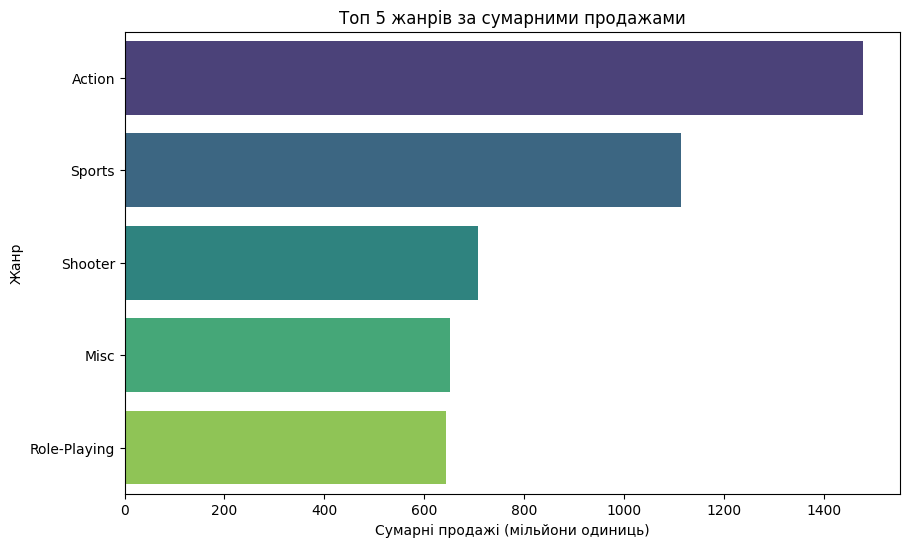

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.barplot(x='Global_Sales', y='Genre', data=genre_sales.head(5), palette='viridis', hue='Genre')
plt.title('Топ 5 жанрів за сумарними продажами')
plt.xlabel('Сумарні продажі (мільйони одиниць)')
plt.ylabel('Жанр')
plt.show()

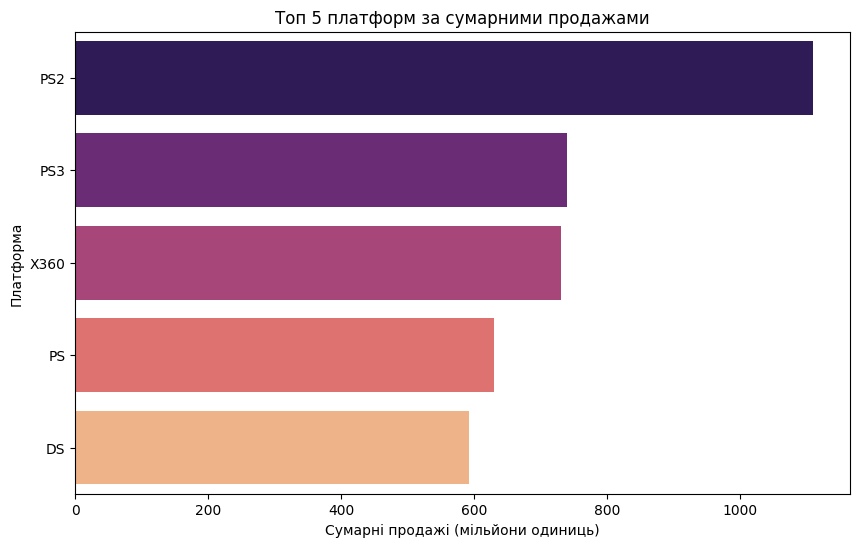

In [27]:
plt.figure(figsize=(10, 6))
sns.barplot(x='Global_Sales', y='Platform', data=platform_sales.head(5), palette='magma', hue='Platform')
plt.title('Топ 5 платформ за сумарними продажами')
plt.xlabel('Сумарні продажі (мільйони одиниць)')
plt.ylabel('Платформа')
plt.show()

In [28]:
genre_avg_sales = df.groupby('Genre')['Global_Sales'].mean().sort_values(ascending=False).reset_index()
print("Топ 5 жанрів за середніми продажами:")
print(genre_avg_sales.head(5))
platform_avg_sales = df.groupby('Platform')['Global_Sales'].mean().sort_values(ascending=False).reset_index()
print("Топ 5 платформ за середніми продажами:")
print(platform_avg_sales.head(5))

Топ 5 жанрів за середніми продажами:
      Genre  Global_Sales
0  Platform      0.603500
1   Shooter      0.555012
2    Sports      0.477918
3  Fighting      0.471581
4    Action      0.450094
Топ 5 платформ за середніми продажами:
  Platform  Global_Sales
0      NES      1.583587
1       GB      1.232809
2      GEN      0.858846
3     2600      0.676288
4      PS4      0.636951


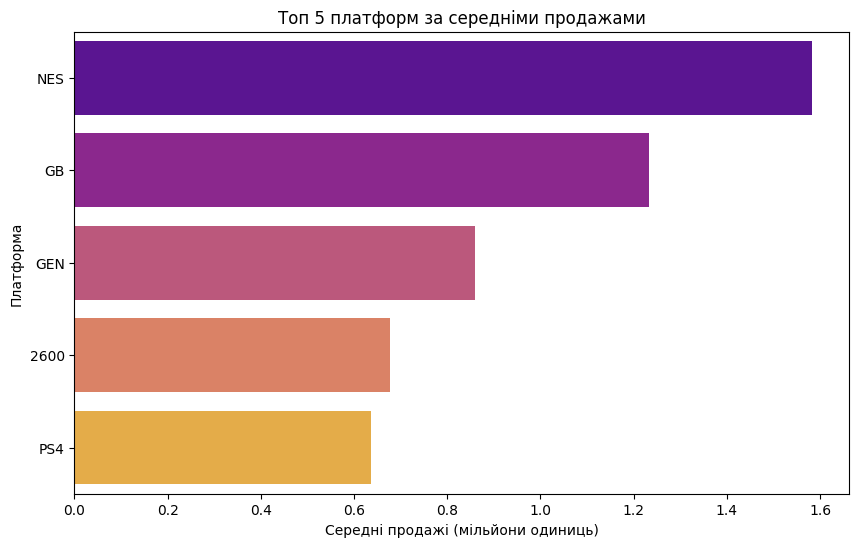

In [29]:
plt.figure(figsize=(10, 6))
sns.barplot(x='Global_Sales', y='Platform', data=platform_avg_sales.head(5), palette='plasma', hue='Platform')
plt.title('Топ 5 платформ за середніми продажами')
plt.xlabel('Середні продажі (мільйони одиниць)')
plt.ylabel('Платформа')
plt.show()

---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------Завдання 2-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [30]:
df['Region'] = df[['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales']].sum(axis=1)

def categorize_region(row):
    if row['NA_Sales'] > row[['EU_Sales', 'JP_Sales', 'Other_Sales']].max():
        return 'NA'
    elif row['EU_Sales'] > row[['NA_Sales', 'JP_Sales', 'Other_Sales']].max():
        return 'EU'
    elif row['JP_Sales'] > row[['NA_Sales', 'EU_Sales', 'Other_Sales']].max():
        return 'JP'
    else:
        return 'Other'

df['Primary_Region'] = df.apply(categorize_region, axis=1)

region_sales = df.groupby('Primary_Region').agg(
    Total_Sales=pd.NamedAgg(column='Global_Sales', aggfunc='sum')
).reset_index()
print("Загальні продажі за регіонами:")
print(region_sales)

Загальні продажі за регіонами:
  Primary_Region  Total_Sales
0             EU      1200.34
1             JP       966.67
2             NA      4675.96
3          Other       117.04


In [31]:
region_sales_sorted = region_sales.sort_values(by='Total_Sales', ascending=False).reset_index(drop=True)

print("Регiони за сумарними продажами (від найбільшого до найменшого):")
print(region_sales_sorted)

Регiони за сумарними продажами (від найбільшого до найменшого):
  Primary_Region  Total_Sales
0             NA      4675.96
1             EU      1200.34
2             JP       966.67
3          Other       117.04


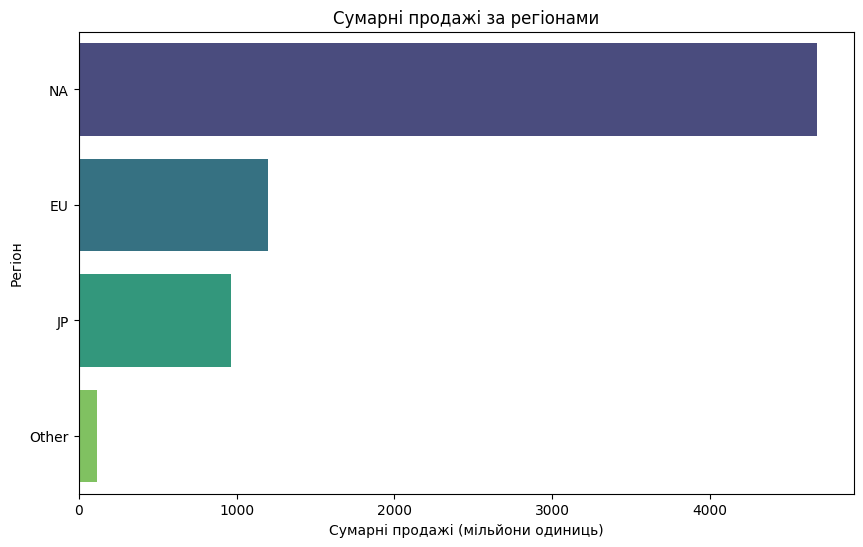

In [32]:
plt.figure(figsize=(10, 6))
sns.barplot(x='Total_Sales', y='Primary_Region', data=region_sales_sorted, palette='viridis', hue='Primary_Region')
plt.title('Сумарні продажі за регіонами')
plt.xlabel('Сумарні продажі (мільйони одиниць)')
plt.ylabel('Регіон')
plt.show()

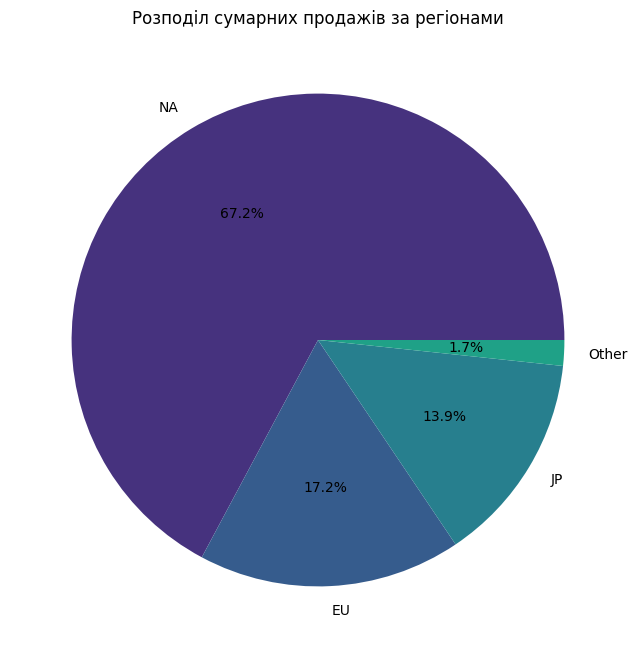

In [33]:
plt.figure(figsize=(8, 8))
plt.pie(region_sales_sorted['Total_Sales'], labels=region_sales_sorted['Primary_Region'], autopct='%1.1f%%', colors=sns.color_palette('viridis'))
plt.title('Розподіл сумарних продажів за регіонами')
plt.show()

In [34]:
top_region = region_sales_sorted.iloc[0]
print(f"Найуспішніший регіон: {top_region['Primary_Region']} з сумарними продажами {top_region['Total_Sales']} мільйонів одиниць.")

Найуспішніший регіон: NA з сумарними продажами 4675.96 мільйонів одиниць.


In [35]:
def categorize_region(row):
    regions = {
        'NA': row['NA_Sales'],
        'EU': row['EU_Sales'],
        'JP': row['JP_Sales'],
        'Other': row['Other_Sales']
    }
    primary_region = max(regions, key=regions.get)
    return primary_region

df['Primary_Region'] = df.apply(categorize_region, axis=1)

region_sales = df.groupby('Primary_Region').agg(
    Total_Sales=pd.NamedAgg(column='Global_Sales', aggfunc='sum')
).reset_index()

print("Загальні продажі за регіонами:")
print(region_sales)

Загальні продажі за регіонами:
  Primary_Region  Total_Sales
0             EU      1203.10
1             JP       966.77
2             NA      4723.85
3          Other        66.29


In [36]:
region_sales_sorted = region_sales.sort_values(by='Total_Sales', ascending=False).reset_index(drop=True)
print("Регіони за сумарними продажами (від найбільшого до найменшого):")
print(region_sales_sorted)

Регіони за сумарними продажами (від найбільшого до найменшого):
  Primary_Region  Total_Sales
0             NA      4723.85
1             EU      1203.10
2             JP       966.77
3          Other        66.29


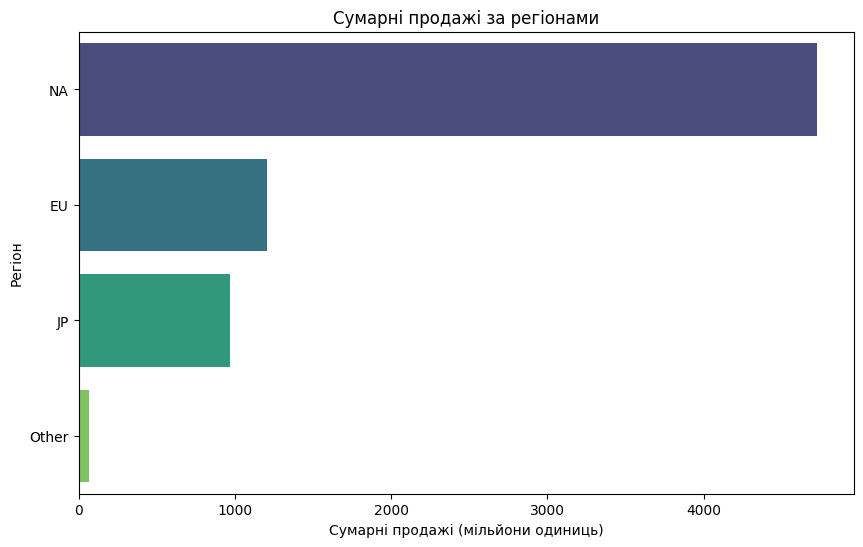

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(10, 6))
sns.barplot(x='Total_Sales', y='Primary_Region', data=region_sales_sorted, palette='viridis', hue='Primary_Region')
plt.title('Сумарні продажі за регіонами')
plt.xlabel('Сумарні продажі (мільйони одиниць)')
plt.ylabel('Регіон')
plt.show()

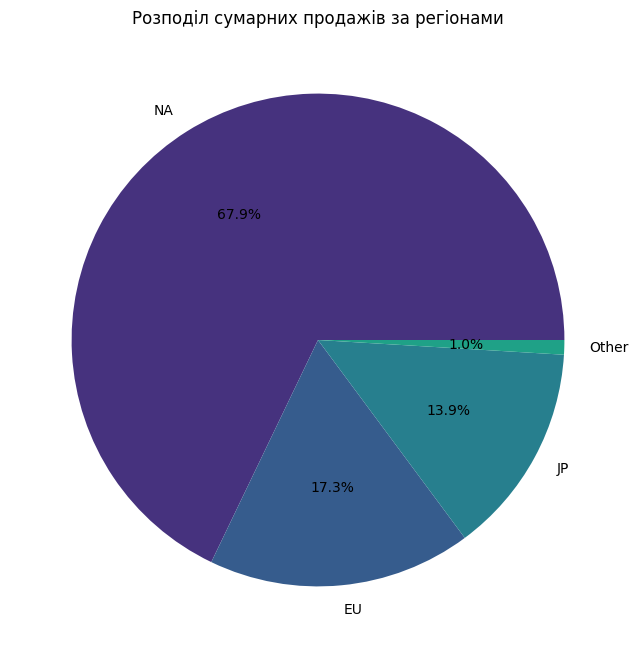

In [38]:
plt.figure(figsize=(8, 8))
plt.pie(region_sales_sorted['Total_Sales'], labels=region_sales_sorted['Primary_Region'], autopct='%1.1f%%', colors=sns.color_palette('viridis'))
plt.title('Розподіл сумарних продажів за регіонами')
plt.show()

In [39]:
top_region = region_sales_sorted.iloc[0]
print(f"Найуспішніший регіон: {top_region['Primary_Region']} з сумарними продажами {top_region['Total_Sales']} мільйонів одиниць.")



Найуспішніший регіон: NA з сумарними продажами 4723.85 мільйонів одиниць.


In [40]:
numerical_cols = ['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales']
corr_matrix = df[numerical_cols].corr()
print("Кореляційна матриця:")
print(corr_matrix)

Кореляційна матриця:
              NA_Sales  EU_Sales  JP_Sales  Other_Sales  Global_Sales
NA_Sales      1.000000  0.619901  0.093079     0.536036      0.882119
EU_Sales      0.619901  1.000000  0.087134     0.667529      0.825695
JP_Sales      0.093079  0.087134  1.000000     0.073947      0.385867
Other_Sales   0.536036  0.667529  0.073947     1.000000      0.700921
Global_Sales  0.882119  0.825695  0.385867     0.700921      1.000000


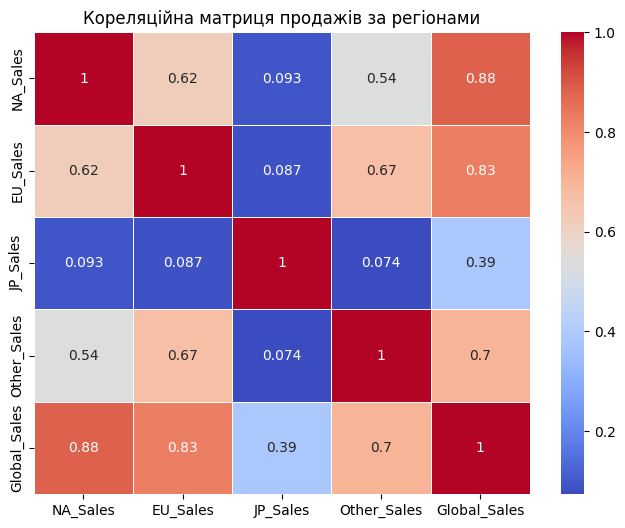

In [41]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Кореляційна матриця продажів за регіонами')
plt.show()

In [42]:
genre_platform_region_sales = df.groupby(['Genre', 'Platform', 'Primary_Region']).agg(
    Total_Sales=pd.NamedAgg(column='Global_Sales', aggfunc='sum')
).reset_index()

print("Агреговані продажі за жанрами, платформами та регіонами:")
print(genre_platform_region_sales.head(10))

Агреговані продажі за жанрами, платформами та регіонами:
    Genre Platform Primary_Region  Total_Sales
0  Action     2600             NA        29.34
1  Action      3DS             EU         3.83
2  Action      3DS             JP        18.49
3  Action      3DS             NA        34.70
4  Action       DC             JP         1.26
5  Action       DS             EU        12.10
6  Action       DS             JP         7.50
7  Action       DS             NA        84.06
8  Action       GB             JP         0.44
9  Action       GB             NA         7.48


In [43]:
import numpy as np
genre_dummies = pd.get_dummies(df['Genre'], prefix='Genre')
platform_dummies = pd.get_dummies(df['Platform'], prefix='Platform')
df_encoded = pd.concat([df, genre_dummies, platform_dummies], axis=1)
numeric_columns = ['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales'] + list(genre_dummies.columns) + list(platform_dummies.columns)
corr_matrix_extended = df_encoded[numeric_columns].corr()
print("Кореляційна матриця з жанрами та платформами:")
print(corr_matrix_extended)

Кореляційна матриця з жанрами та платформами:
                    NA_Sales  EU_Sales  JP_Sales  Other_Sales  Global_Sales  \
NA_Sales            1.000000  0.619901  0.093079     0.536036      0.882119   
EU_Sales            0.619901  1.000000  0.087134     0.667529      0.825695   
JP_Sales            0.093079  0.087134  1.000000     0.073947      0.385867   
Other_Sales         0.536036  0.667529  0.073947     1.000000      0.700921   
Global_Sales        0.882119  0.825695  0.385867     0.700921      1.000000   
Genre_Action        0.024308  0.039442 -0.046945     0.035478      0.019057   
Genre_Adventure    -0.103655 -0.077271 -0.034558    -0.076814     -0.106482   
Genre_Fighting      0.015301 -0.004842  0.028894     0.007547      0.016131   
Genre_Misc         -0.014956 -0.024570 -0.015401    -0.008366     -0.022845   
Genre_Platform      0.067907  0.036928  0.031165     0.009047      0.061528   
Genre_Puzzle       -0.032873 -0.035341  0.011728    -0.040902     -0.033195   
Genre_

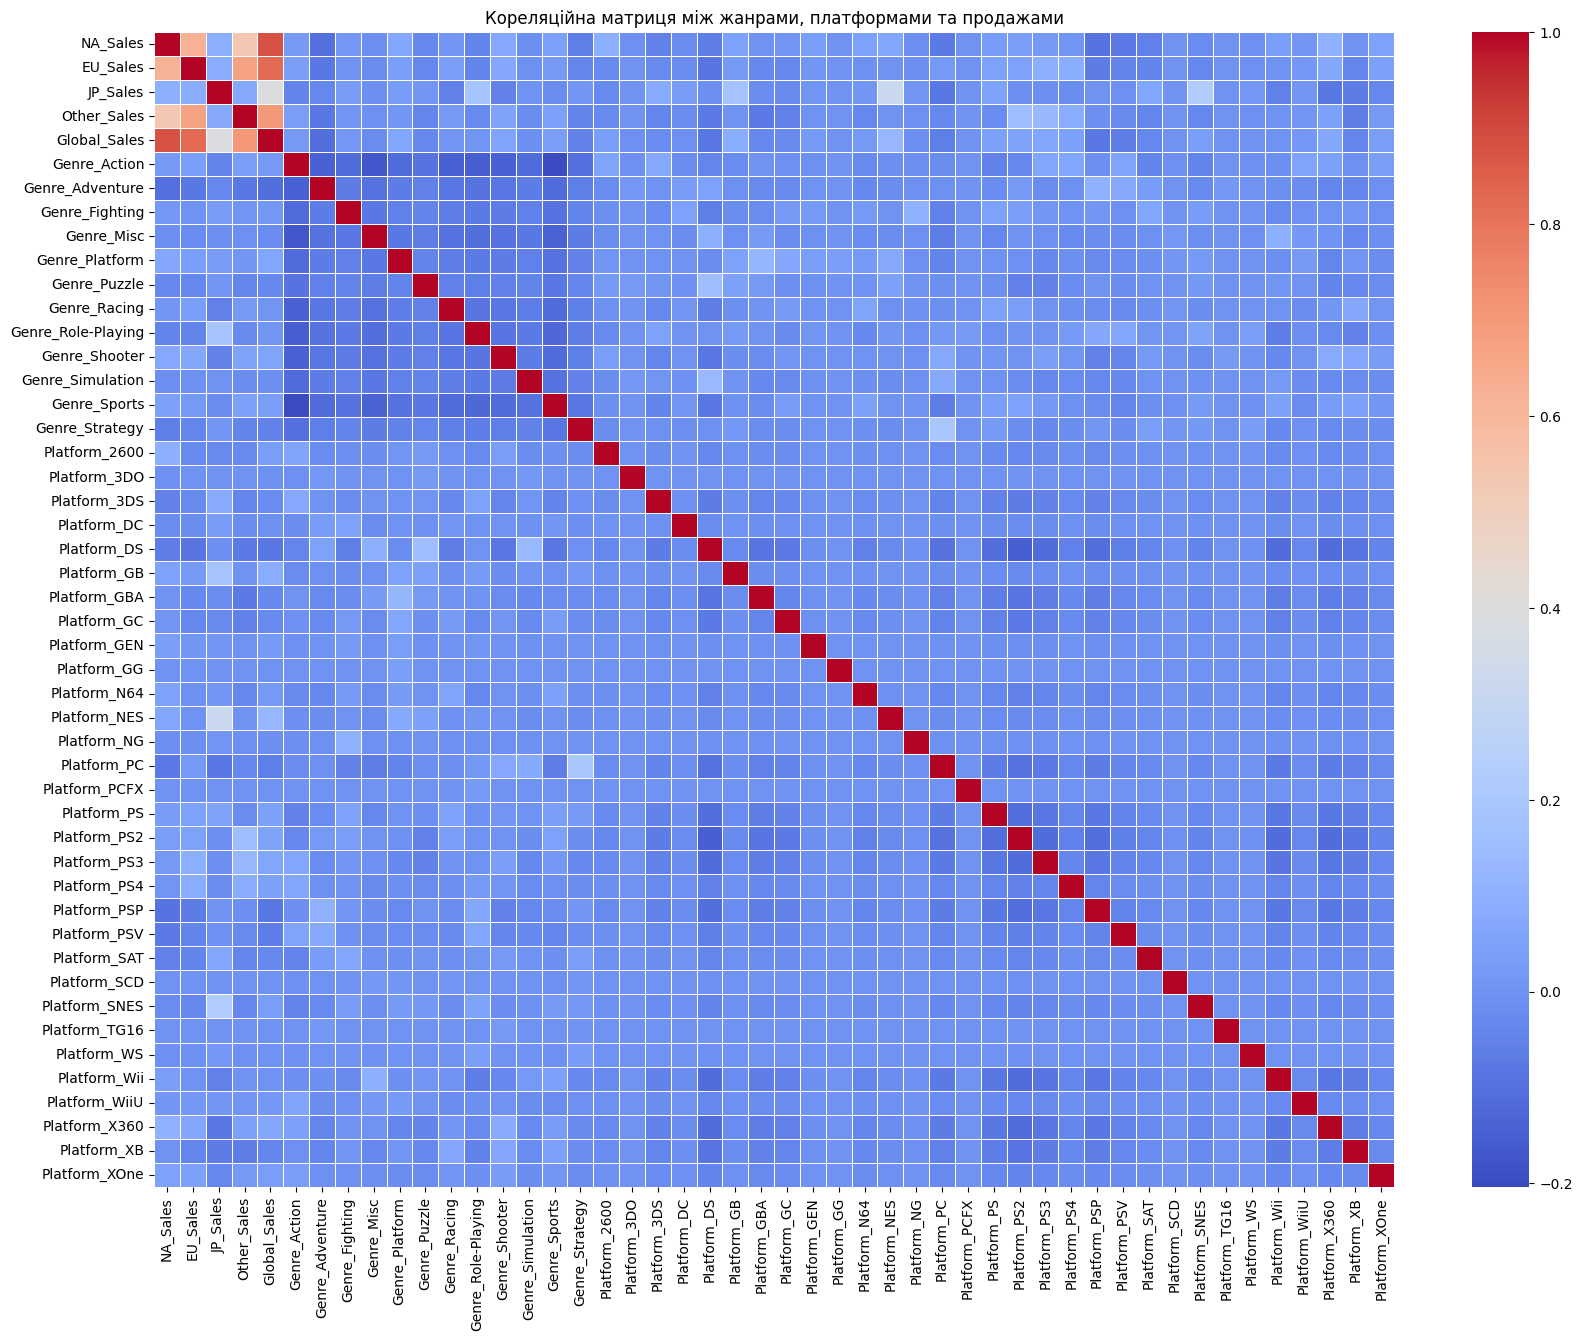

In [44]:
plt.figure(figsize=(20, 15))
sns.heatmap(corr_matrix_extended, annot=False, cmap='coolwarm', linewidths=0.5)
plt.title('Кореляційна матриця між жанрами, платформами та продажами')
plt.show()

In [45]:
df['Year'] = pd.to_datetime(df['Year'], format='%Y', errors='coerce')
df = df.dropna(subset=['Year'])
df.set_index('Year', inplace=True)

annual_sales = df.resample('YE').agg(
    Total_Global_Sales=pd.NamedAgg(column='Global_Sales', aggfunc='sum'),
    Total_NA_Sales=pd.NamedAgg(column='NA_Sales', aggfunc='sum'),
    Total_EU_Sales=pd.NamedAgg(column='EU_Sales', aggfunc='sum'),
    Total_JP_Sales=pd.NamedAgg(column='JP_Sales', aggfunc='sum'),
    Total_Other_Sales=pd.NamedAgg(column='Other_Sales', aggfunc='sum')
)

print(annual_sales.head())

            Total_Global_Sales  Total_NA_Sales  Total_EU_Sales  \
Year                                                             
1980-12-31               11.38           10.59            0.67   
1981-12-31               35.77           33.40            1.96   
1982-12-31               21.05           19.64            1.20   
1983-12-31               16.79            7.76            0.80   
1984-12-31               22.05            6.35            1.47   

            Total_JP_Sales  Total_Other_Sales  
Year                                           
1980-12-31            0.00               0.12  
1981-12-31            0.00               0.32  
1982-12-31            0.00               0.23  
1983-12-31            8.10               0.14  
1984-12-31           13.99               0.23  


In [46]:
annual_sales['Prev_Total_Global_Sales'] = annual_sales['Total_Global_Sales'].shift(1)
annual_sales['Prev_Total_NA_Sales'] = annual_sales['Total_NA_Sales'].shift(1)
annual_sales['Prev_Total_EU_Sales'] = annual_sales['Total_EU_Sales'].shift(1)
annual_sales['Prev_Total_JP_Sales'] = annual_sales['Total_JP_Sales'].shift(1)
annual_sales['Prev_Total_Other_Sales'] = annual_sales['Total_Other_Sales'].shift(1)

print(annual_sales.head())

            Total_Global_Sales  Total_NA_Sales  Total_EU_Sales  \
Year                                                             
1980-12-31               11.38           10.59            0.67   
1981-12-31               35.77           33.40            1.96   
1982-12-31               21.05           19.64            1.20   
1983-12-31               16.79            7.76            0.80   
1984-12-31               22.05            6.35            1.47   

            Total_JP_Sales  Total_Other_Sales  Prev_Total_Global_Sales  \
Year                                                                     
1980-12-31            0.00               0.12                      NaN   
1981-12-31            0.00               0.32                    11.38   
1982-12-31            0.00               0.23                    35.77   
1983-12-31            8.10               0.14                    21.05   
1984-12-31           13.99               0.23                    16.79   

            Prev_T

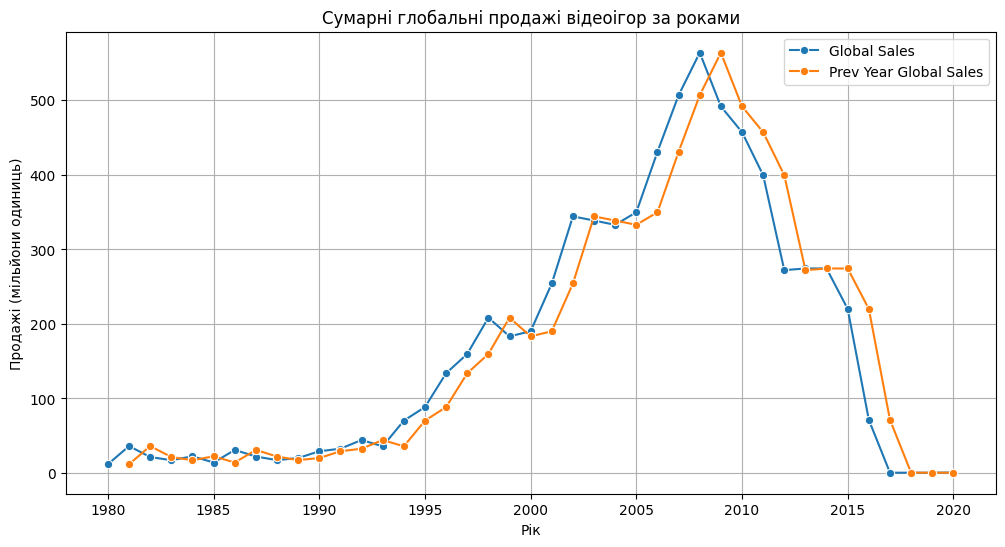

In [47]:
plt.figure(figsize=(12, 6))
sns.lineplot(data=annual_sales, x=annual_sales.index.year, y='Total_Global_Sales', marker='o', label='Global Sales')
sns.lineplot(data=annual_sales, x=annual_sales.index.year, y='Prev_Total_Global_Sales', marker='o', label='Prev Year Global Sales')
plt.title('Сумарні глобальні продажі відеоігор за роками')
plt.xlabel('Рік')
plt.ylabel('Продажі (мільйони одиниць)')
plt.legend()
plt.grid(True)
plt.show()

In [48]:
annual_sales['Growth_Global_Sales'] = (annual_sales['Total_Global_Sales'] - annual_sales['Prev_Total_Global_Sales']) / annual_sales['Prev_Total_Global_Sales'] * 100
print(annual_sales.head())

            Total_Global_Sales  Total_NA_Sales  Total_EU_Sales  \
Year                                                             
1980-12-31               11.38           10.59            0.67   
1981-12-31               35.77           33.40            1.96   
1982-12-31               21.05           19.64            1.20   
1983-12-31               16.79            7.76            0.80   
1984-12-31               22.05            6.35            1.47   

            Total_JP_Sales  Total_Other_Sales  Prev_Total_Global_Sales  \
Year                                                                     
1980-12-31            0.00               0.12                      NaN   
1981-12-31            0.00               0.32                    11.38   
1982-12-31            0.00               0.23                    35.77   
1983-12-31            8.10               0.14                    21.05   
1984-12-31           13.99               0.23                    16.79   

            Prev_T

/var/folders/c1/3w211ppn47b30jn4_6r8ghzh0000gn/T/ipykernel_23067/925522001.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Year', y='Growth_Global_Sales', data=annual_sales, palette='coolwarm')


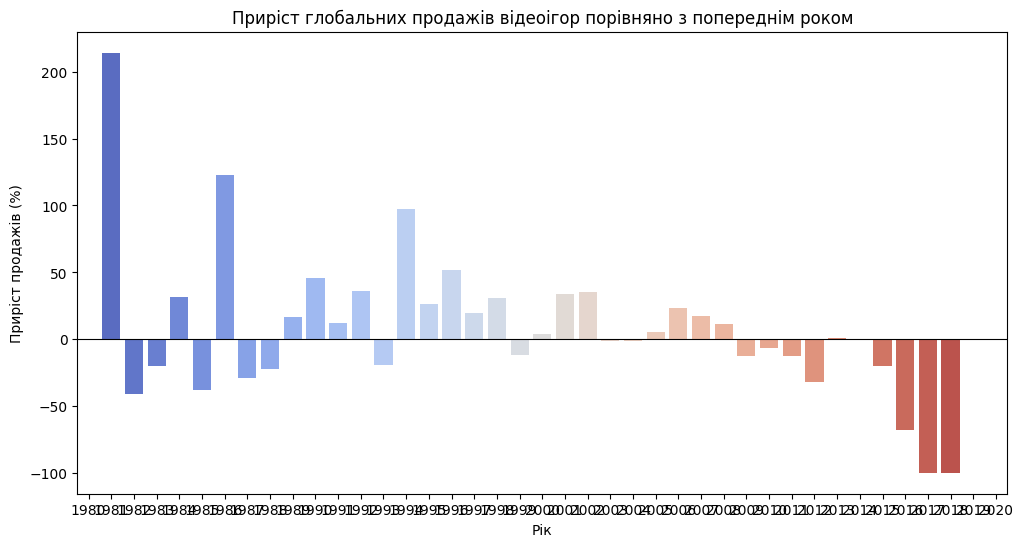

In [49]:
plt.figure(figsize=(12, 6))
annual_sales['Year'] = annual_sales.index.year  # Extract the year from the DateTime index
sns.barplot(x='Year', y='Growth_Global_Sales', data=annual_sales, palette='coolwarm')
plt.title('Приріст глобальних продажів відеоігор порівняно з попереднім роком')
plt.xlabel('Рік')
plt.ylabel('Приріст продажів (%)')
plt.axhline(0, color='black', linewidth=0.8)
plt.show()



------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------Завдання 3-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [50]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set(style="whitegrid")

In [51]:
annual_sales = pd.read_csv('Video_Game_Sales_Final.csv', parse_dates=['Year'], index_col='Year')
print(annual_sales.head())

            Rank                            Name Platform         Genre  \
Year                                                                      
2012-01-01   182                      Diablo III       PC  Role-Playing   
2003-01-01   183             Super Mario Bros. 3      GBA      Platform   
2012-01-01   184         New Super Mario Bros. U     WiiU      Platform   
1994-01-01   185  Super Mario Land 3: Wario Land       GB      Platform   
2012-01-01   186                  FIFA Soccer 13     X360        Action   

                  Publisher  NA_Sales  EU_Sales  JP_Sales  Other_Sales  \
Year                                                                     
2012-01-01       Activision      2.43      2.15      0.00         0.62   
2003-01-01         Nintendo      2.93      1.25      0.83         0.20   
2012-01-01         Nintendo      2.32      1.30      1.27         0.31   
1994-01-01         Nintendo      2.49      0.98      1.57         0.15   
2012-01-01  Electronic Arts   

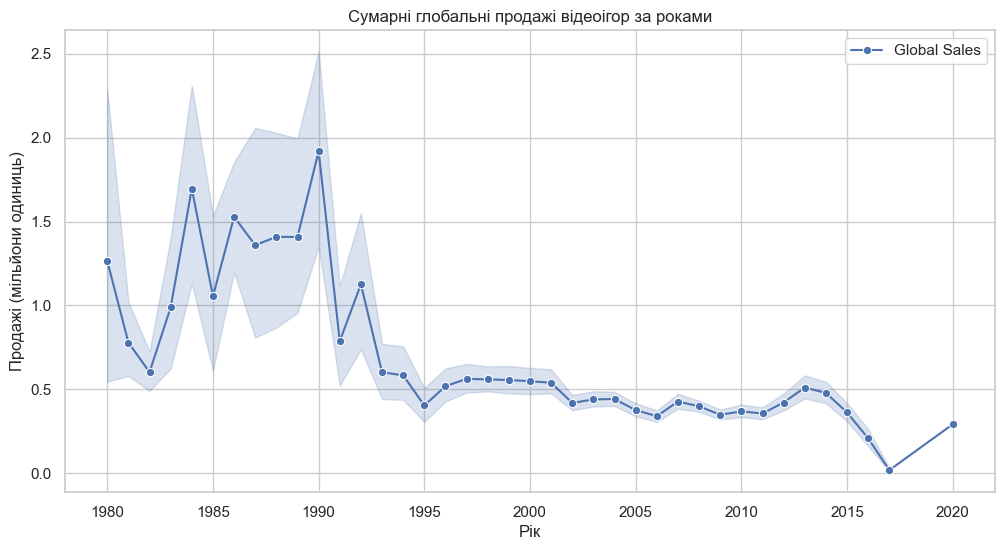

In [52]:
plt.figure(figsize=(12, 6))
sns.lineplot(data=annual_sales, x=annual_sales.index.year, y='Global_Sales', marker='o', label='Global Sales')
plt.title('Сумарні глобальні продажі відеоігор за роками')
plt.xlabel('Рік')
plt.ylabel('Продажі (мільйони одиниць)')
plt.legend()
plt.show()

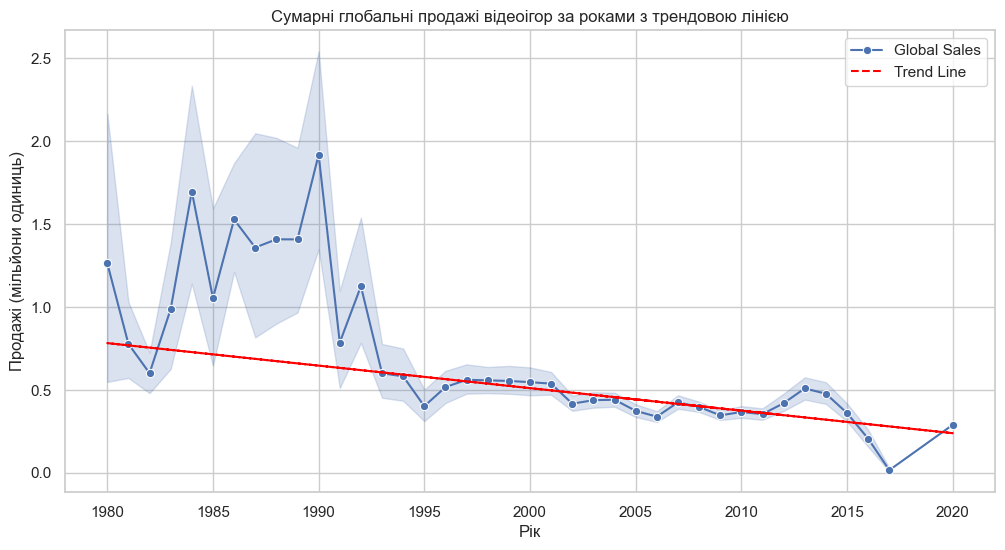

In [53]:
x = annual_sales.index.year
y = annual_sales['Global_Sales']
coefficients = np.polyfit(x, y, 1)
poly = np.poly1d(coefficients)

trend_line = poly(x)

plt.figure(figsize=(12, 6))
sns.lineplot(x=x, y=y, marker='o', label='Global Sales')
plt.plot(x, trend_line, color='red', linestyle='--', label='Trend Line')
plt.title('Сумарні глобальні продажі відеоігор за роками з трендовою лінією')
plt.xlabel('Рік')
plt.ylabel('Продажі (мільйони одиниць)')
plt.legend()
plt.show()

In [54]:
genre_sales = df.groupby('Genre')['Global_Sales'].sum().reset_index()

genre_sales_sorted = genre_sales.sort_values(by='Global_Sales', ascending=False)

top_genres = genre_sales_sorted.head(10)
print(top_genres)

           Genre  Global_Sales
0         Action       1478.56
10        Sports       1115.46
8        Shooter        708.75
3           Misc        652.41
7   Role-Playing        644.47
6         Racing        545.12
4       Platform        519.01
2       Fighting        396.60
9     Simulation        332.25
1      Adventure        222.31


In [55]:
platform_sales = df.groupby('Platform')['Global_Sales'].sum().reset_index()

platform_sales_sorted = platform_sales.sort_values(by='Global_Sales', ascending=False)

top_platforms = platform_sales_sorted.head(10)
print(top_platforms)

   Platform  Global_Sales
16      PS2       1110.41
17      PS3        740.35
28     X360        730.36
15       PS        629.55
4        DS        591.83
26      Wii        555.07
19      PSP        283.06
6       GBA        269.33
13       PC        244.43
29       XB        243.34


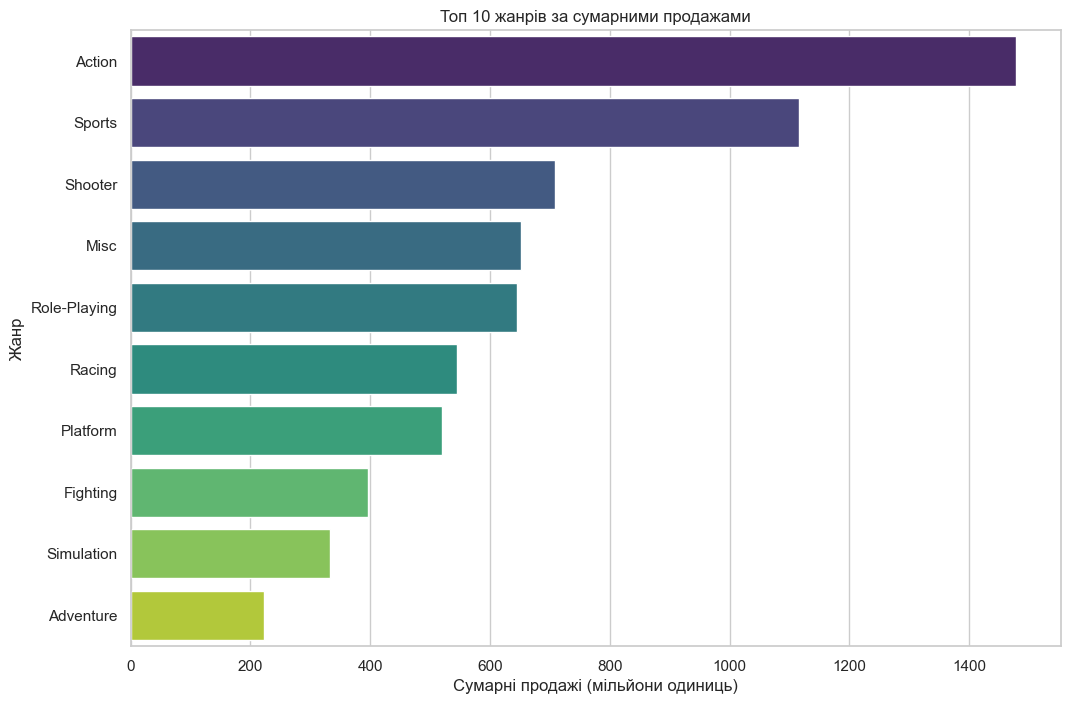

In [56]:
plt.figure(figsize=(12, 8))
sns.barplot(x='Global_Sales', y='Genre', data=top_genres, palette='viridis', hue='Genre')
plt.title('Топ 10 жанрів за сумарними продажами')
plt.xlabel('Сумарні продажі (мільйони одиниць)')
plt.ylabel('Жанр')
plt.show()

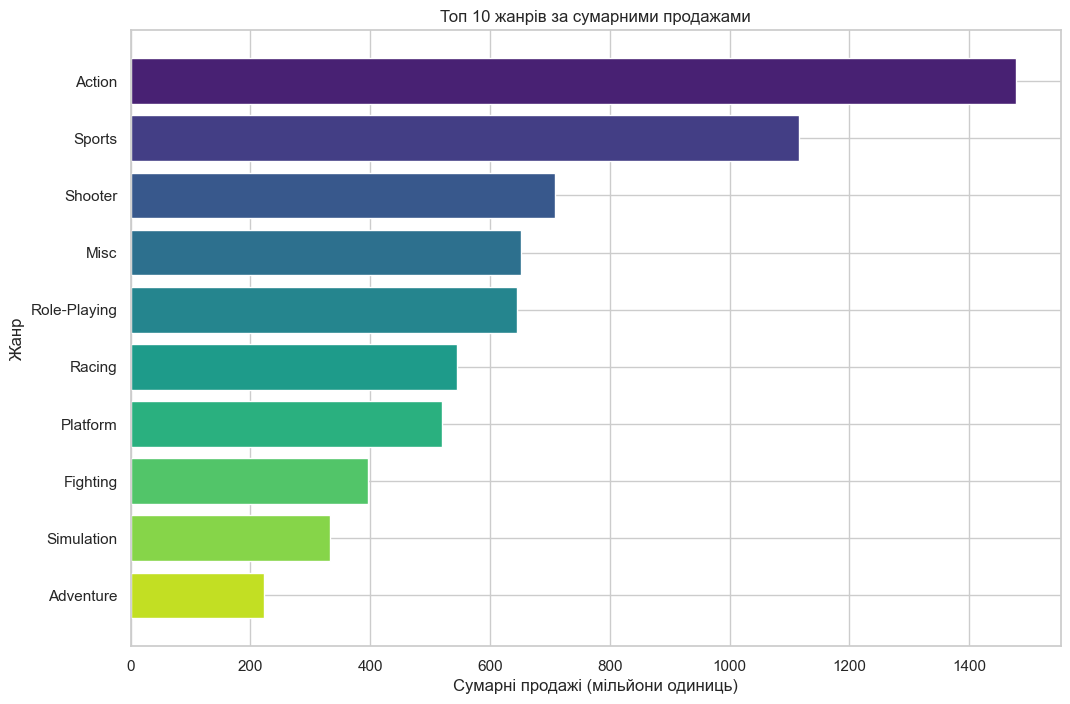

In [57]:
plt.figure(figsize=(12, 8))
plt.barh(top_genres['Genre'], top_genres['Global_Sales'], color=sns.color_palette('viridis', len(top_genres)))
plt.title('Топ 10 жанрів за сумарними продажами')
plt.xlabel('Сумарні продажі (мільйони одиниць)')
plt.ylabel('Жанр')
plt.gca().invert_yaxis()
plt.show()

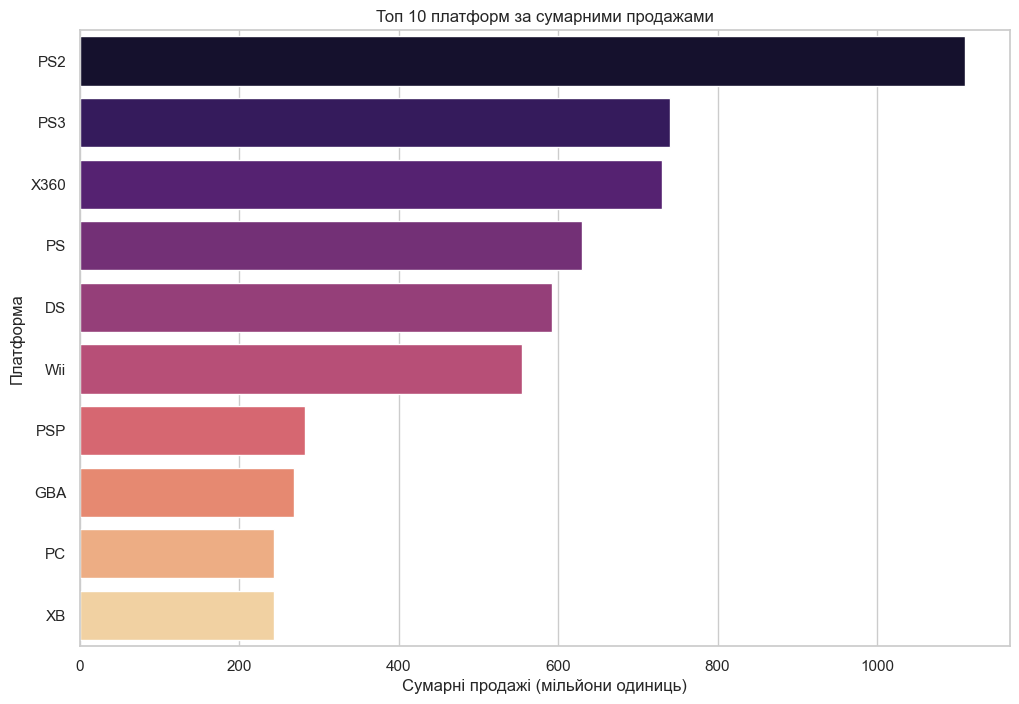

In [58]:
plt.figure(figsize=(12, 8))
sns.barplot(x='Global_Sales', y='Platform', data=top_platforms, palette='magma', hue='Platform')
plt.title('Топ 10 платформ за сумарними продажами')
plt.xlabel('Сумарні продажі (мільйони одиниць)')
plt.ylabel('Платформа')
plt.show()

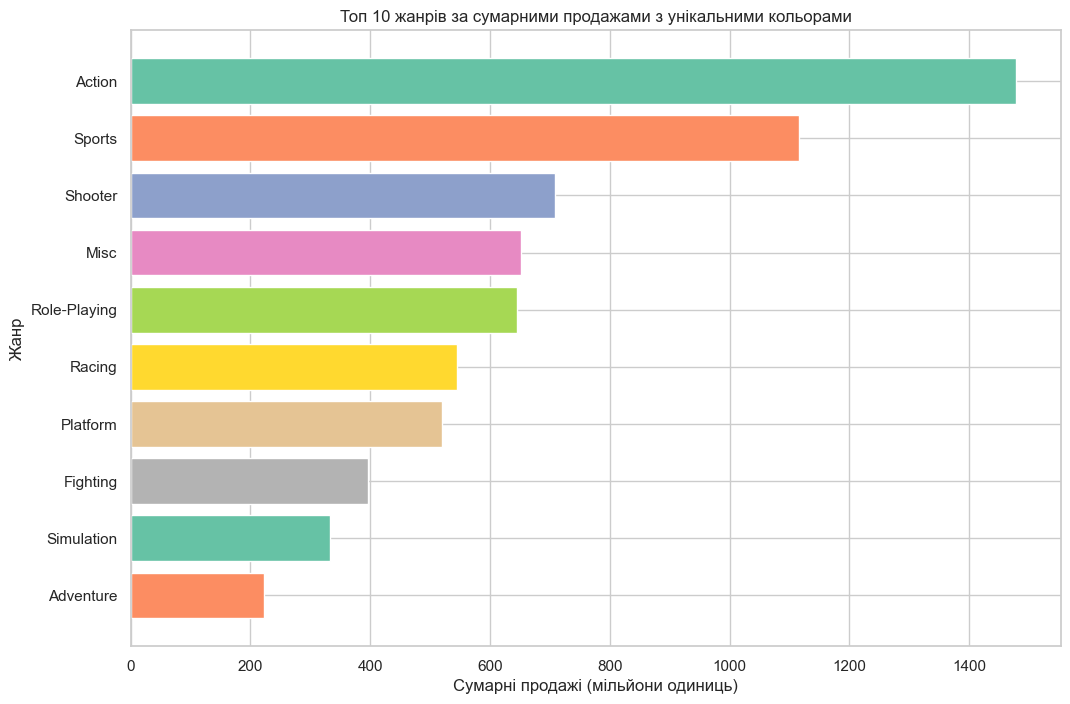

In [59]:
colors_genres = sns.color_palette('Set2', len(top_genres))

plt.figure(figsize=(12, 8))
plt.barh(top_genres['Genre'], top_genres['Global_Sales'], color=colors_genres)
plt.title('Топ 10 жанрів за сумарними продажами з унікальними кольорами')
plt.xlabel('Сумарні продажі (мільйони одиниць)')
plt.ylabel('Жанр')
plt.gca().invert_yaxis()
plt.show()

In [60]:
genre_sales = df.groupby('Genre')['Global_Sales'].apply(list).reset_index()
print(genre_sales)

           Genre                                       Global_Sales
0         Action  [5.18, 5.17, 5.11, 5.08, 5.08, 5.05, 4.94, 4.9...
1      Adventure  [4.83, 4.38, 3.34, 3.23, 3.16, 3.12, 2.81, 2.7...
2       Fighting  [5.02, 4.19, 4.1, 4.05, 3.87, 3.58, 3.44, 3.36...
3           Misc  [5.12, 4.98, 4.62, 4.53, 4.44, 4.42, 4.24, 4.2...
4       Platform  [5.2, 5.19, 5.19, 5.15, 5.13, 5.07, 5.0, 4.5, ...
5         Puzzle  [4.85, 4.0, 3.36, 2.94, 2.92, 2.79, 2.69, 2.4,...
6         Racing  [4.88, 4.79, 4.7, 4.64, 4.37, 4.2, 4.16, 4.06,...
7   Role-Playing  [5.2, 5.13, 4.96, 4.96, 4.87, 4.47, 4.39, 4.33...
8        Shooter  [5.13, 5.13, 5.0, 4.57, 4.45, 4.35, 4.31, 4.31...
9     Simulation  [5.15, 5.12, 4.68, 3.81, 3.76, 3.69, 3.63, 3.6...
10        Sports  [5.14, 5.08, 5.02, 4.91, 4.82, 4.77, 4.68, 4.5...
11      Strategy  [5.01, 4.83, 4.21, 3.7, 2.85, 2.73, 2.63, 2.4,...


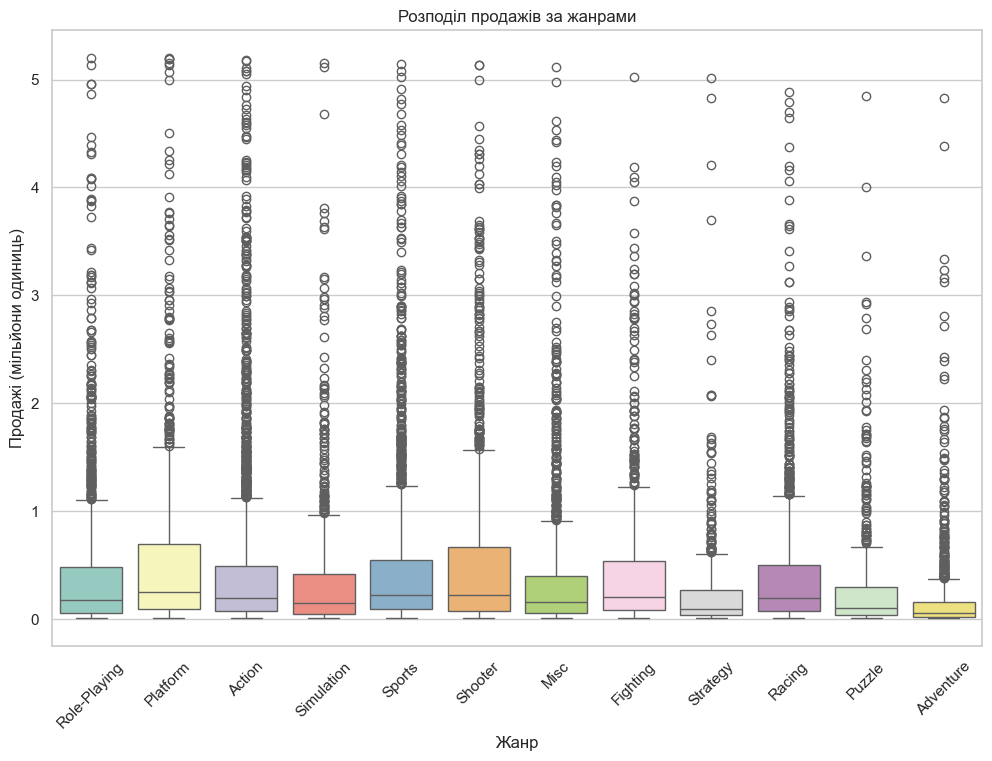

In [61]:
plt.figure(figsize=(12, 8))
sns.boxplot(x='Genre', y='Global_Sales', data=df, palette='Set3',hue='Genre')
plt.title('Розподіл продажів за жанрами')
plt.xlabel('Жанр')
plt.ylabel('Продажі (мільйони одиниць)')
plt.xticks(rotation=45)
plt.show()

In [62]:
platform_sales = df.groupby('Platform')['Global_Sales'].apply(list).reset_index()
print(platform_sales)

   Platform                                       Global_Sales
0      2600  [4.5, 4.31, 2.76, 2.53, 2.2, 2.13, 1.97, 1.65,...
1       3DO                                 [0.06, 0.02, 0.02]
2       3DS  [5.15, 4.58, 4.21, 3.89, 3.81, 3.44, 3.26, 3.2...
3        DC  [2.42, 1.81, 1.2, 1.18, 1.14, 1.09, 0.52, 0.41...
4        DS  [5.17, 5.14, 4.96, 4.9, 4.0, 3.84, 3.83, 3.69,...
5        GB  [5.19, 5.13, 5.07, 3.91, 3.83, 3.7, 3.41, 3.07...
6       GBA  [5.2, 4.24, 2.94, 2.91, 2.82, 2.7, 2.39, 2.27,...
7        GC  [4.6, 3.6, 3.15, 2.82, 2.56, 2.54, 2.47, 2.25,...
8       GEN  [4.34, 2.67, 2.6, 2.05, 1.82, 1.76, 1.66, 1.41...
9        GG                                             [0.04]
10      N64  [4.88, 4.03, 3.65, 3.63, 3.36, 3.12, 2.94, 2.8...
11      NES  [4.85, 4.38, 4.17, 4.16, 4.01, 3.87, 3.5, 3.2,...
12       NG  [0.25, 0.23, 0.2, 0.2, 0.14, 0.12, 0.08, 0.07,...
13       PC  [5.2, 5.12, 4.83, 4.21, 4.12, 4.09, 3.88, 3.76...
14     PCFX                                            

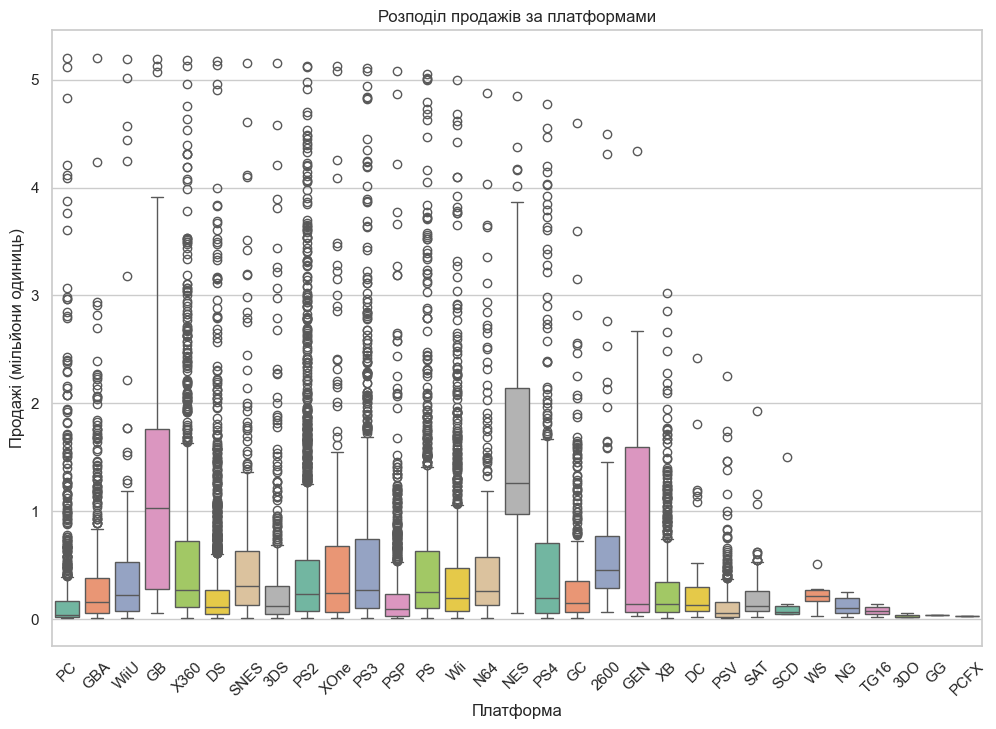

In [63]:
plt.figure(figsize=(12, 8))
sns.boxplot(x='Platform', y='Global_Sales', data=df, palette='Set2',hue='Platform')
plt.title('Розподіл продажів за платформами')
plt.xlabel('Платформа')
plt.ylabel('Продажі (мільйони одиниць)')
plt.xticks(rotation=45)
plt.show()

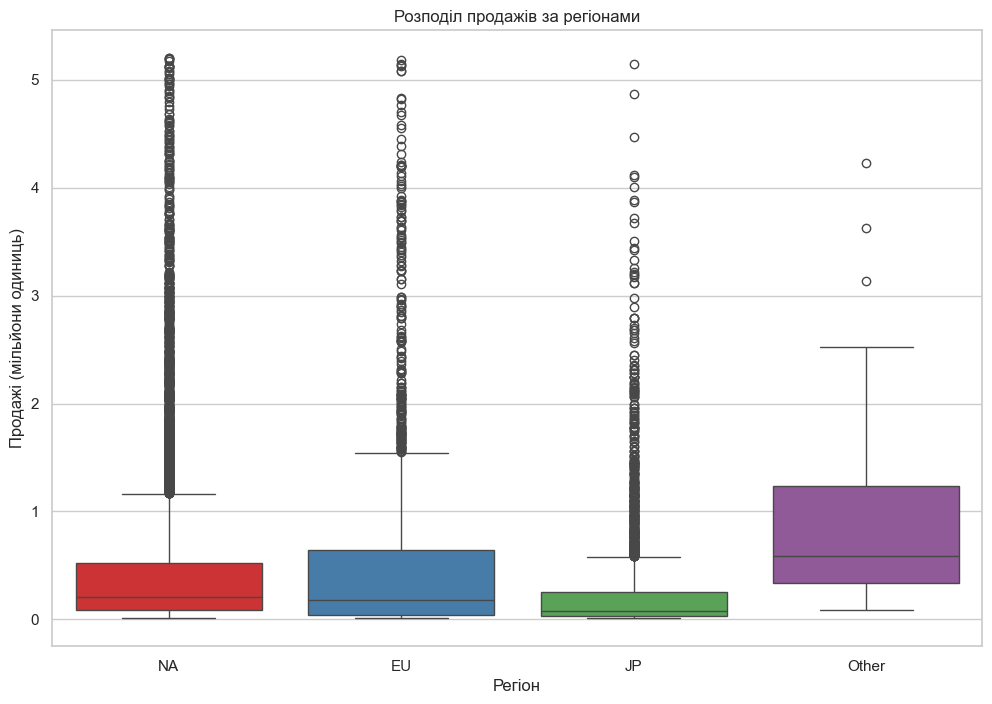

In [64]:
plt.figure(figsize=(12, 8))
sns.boxplot(x='Primary_Region', y='Global_Sales', data=df, palette='Set1', hue='Primary_Region')
plt.title('Розподіл продажів за регіонами')
plt.xlabel('Регіон')
plt.ylabel('Продажі (мільйони одиниць)')
plt.show()

In [65]:
numerical_cols = ['Global_Sales', 'NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales']

corr_matrix = df[numerical_cols].corr()

print("Кореляційна матриця:")
print(corr_matrix)

Кореляційна матриця:
              Global_Sales  NA_Sales  EU_Sales  JP_Sales  Other_Sales
Global_Sales      1.000000  0.882119  0.825695  0.385867     0.700921
NA_Sales          0.882119  1.000000  0.619901  0.093079     0.536036
EU_Sales          0.825695  0.619901  1.000000  0.087134     0.667529
JP_Sales          0.385867  0.093079  0.087134  1.000000     0.073947
Other_Sales       0.700921  0.536036  0.667529  0.073947     1.000000


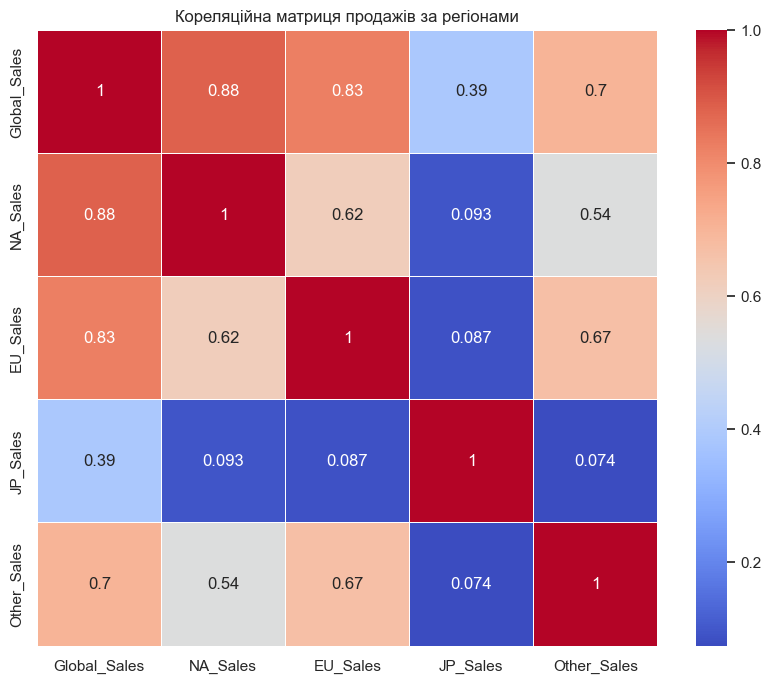

In [66]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Кореляційна матриця продажів за регіонами')
plt.show()

In [67]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

In [68]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go

annual_sales = df.groupby('Year')['Global_Sales'].sum().reset_index()

annual_sales['Year'] = annual_sales['Year'].dt.year

fig = px.line(annual_sales, x='Year', y='Global_Sales',
              title='Сумарні глобальні продажі відеоігор за роками',
              labels={'Global_Sales': 'Продажі (мільйони одиниць)', 'Year': 'Рік'},
              markers=True)

z = np.polyfit(annual_sales['Year'], annual_sales['Global_Sales'], 1)
p = np.poly1d(z)
fig.add_traces(go.Scatter(x=annual_sales['Year'], y=p(annual_sales['Year']),
                          mode='lines',
                          name='Тренд',
                          line=dict(color='red', dash='dash')))

fig.show()


In [69]:
genre_platform_sales = df.groupby(['Genre', 'Platform'])['Global_Sales'].sum().reset_index()
sales_pivot = genre_platform_sales.pivot(index='Genre', columns='Platform', values='Global_Sales').fillna(0)

fig = px.imshow(sales_pivot,
                labels=dict(x="Платформа", y="Жанр", color="Продажі (мільйони)"),
                x=sales_pivot.columns,
                y=sales_pivot.index,
                color_continuous_scale='Viridis',
                title='Теплова карта продажів за жанрами та платформами')

fig.show()

------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------Завдання 3-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [70]:
annual_sales = df.groupby('Year')['Global_Sales'].sum().reset_index()

print(annual_sales.head())

        Year  Global_Sales
0 1980-01-01         11.38
1 1981-01-01         35.77
2 1982-01-01         21.05
3 1983-01-01         16.79
4 1984-01-01         22.05


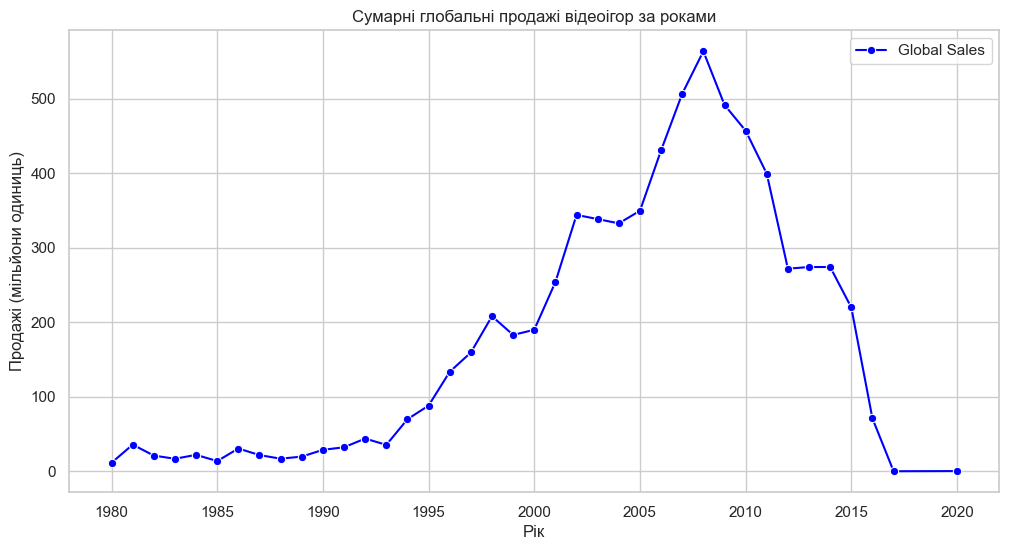

In [71]:
plt.figure(figsize=(12, 6))
sns.lineplot(data=annual_sales, x='Year', y='Global_Sales', marker='o', color='blue', label='Global Sales')
plt.title('Сумарні глобальні продажі відеоігор за роками')
plt.xlabel('Рік')
plt.ylabel('Продажі (мільйони одиниць)')
plt.legend()
plt.show()

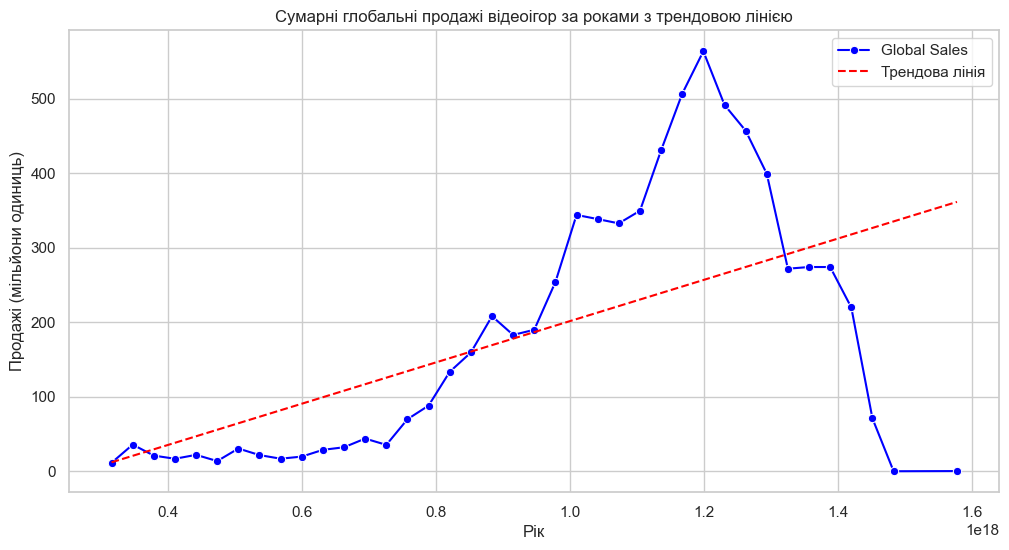

In [74]:
annual_sales['Year'] = annual_sales['Year'].astype(int)
coefficients = np.polyfit(annual_sales['Year'], annual_sales['Global_Sales'], 1)
poly = np.poly1d(coefficients)
poly = np.poly1d(coefficients)
trend_line = poly(annual_sales['Year'])
plt.figure(figsize=(12, 6))
sns.lineplot(data=annual_sales, x='Year', y='Global_Sales', marker='o', color='blue', label='Global Sales')
plt.plot(annual_sales['Year'], trend_line, color='red', linestyle='--', label='Трендова лінія')
plt.title('Сумарні глобальні продажі відеоігор за роками з трендовою лінією')
plt.xlabel('Рік')
plt.ylabel('Продажі (мільйони одиниць)')
plt.legend()
plt.show()

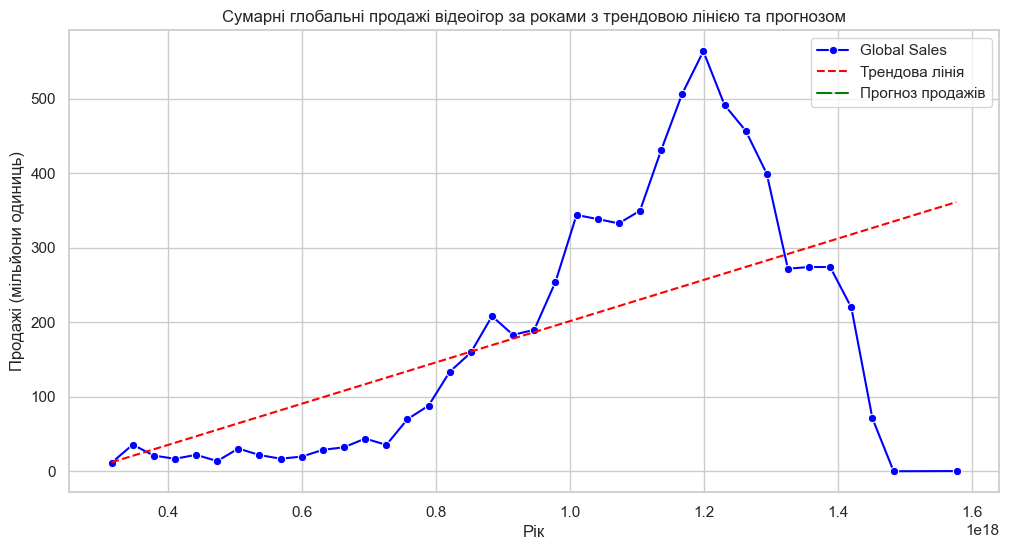

In [75]:
future_years = np.arange(annual_sales['Year'].max() + 1, annual_sales['Year'].max() + 6)
future_sales = poly(future_years)

future_df = pd.DataFrame({
    'Year': future_years,
    'Global_Sales': future_sales
})

plt.figure(figsize=(12, 6))
sns.lineplot(data=annual_sales, x='Year', y='Global_Sales', marker='o', color='blue', label='Global Sales')
plt.plot(annual_sales['Year'], trend_line, color='red', linestyle='--', label='Трендова лінія')
sns.lineplot(data=future_df, x='Year', y='Global_Sales', marker='x', color='green', label='Прогноз продажів')
plt.title('Сумарні глобальні продажі відеоігор за роками з трендовою лінією та прогнозом')
plt.xlabel('Рік')
plt.ylabel('Продажі (мільйони одиниць)')
plt.legend()
plt.show()

In [76]:
genre_sales = df.groupby('Genre')['Global_Sales'].sum().reset_index()
genre_sales_sorted = genre_sales.sort_values(by='Global_Sales', ascending=False)
top_genres = genre_sales_sorted.head(10)
print(top_genres)

           Genre  Global_Sales
0         Action       1478.56
10        Sports       1115.46
8        Shooter        708.75
3           Misc        652.41
7   Role-Playing        644.47
6         Racing        545.12
4       Platform        519.01
2       Fighting        396.60
9     Simulation        332.25
1      Adventure        222.31


In [77]:
platform_sales = df.groupby('Platform')['Global_Sales'].sum().reset_index()

platform_sales_sorted = platform_sales.sort_values(by='Global_Sales', ascending=False)

top_platforms = platform_sales_sorted.head(10)
print(top_platforms)

   Platform  Global_Sales
16      PS2       1110.41
17      PS3        740.35
28     X360        730.36
15       PS        629.55
4        DS        591.83
26      Wii        555.07
19      PSP        283.06
6       GBA        269.33
13       PC        244.43
29       XB        243.34


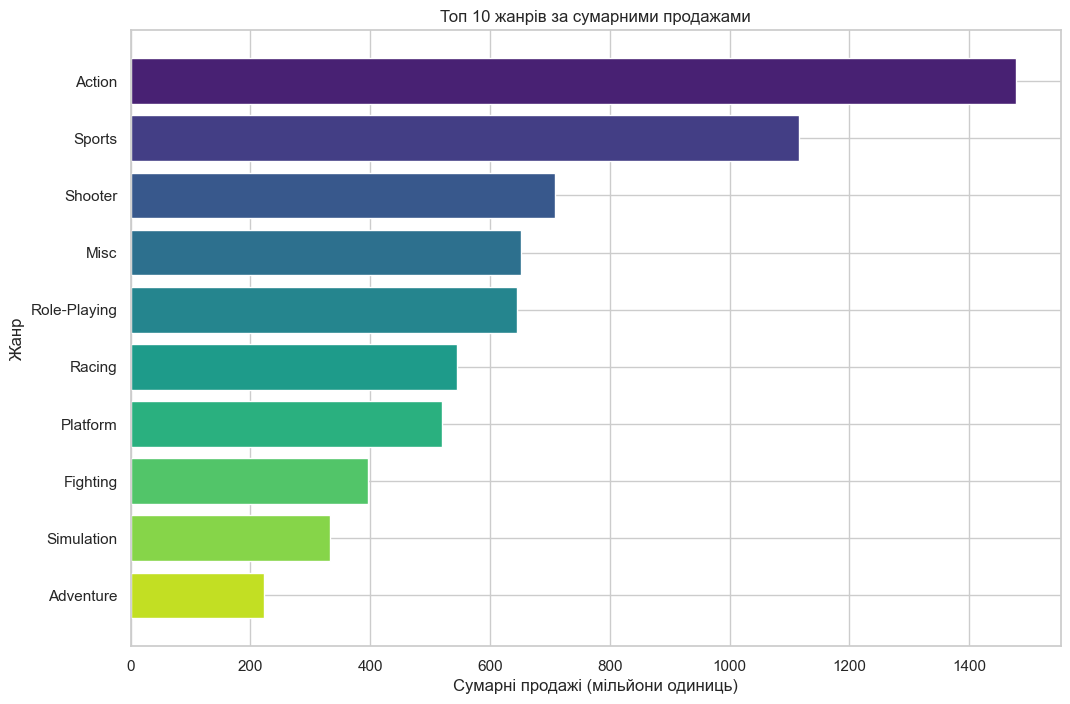

In [78]:
plt.figure(figsize=(12, 8))
plt.barh(top_genres['Genre'], top_genres['Global_Sales'], color=sns.color_palette('viridis', len(top_genres)))
plt.title('Топ 10 жанрів за сумарними продажами')
plt.xlabel('Сумарні продажі (мільйони одиниць)')
plt.ylabel('Жанр')
plt.gca().invert_yaxis()
plt.show()

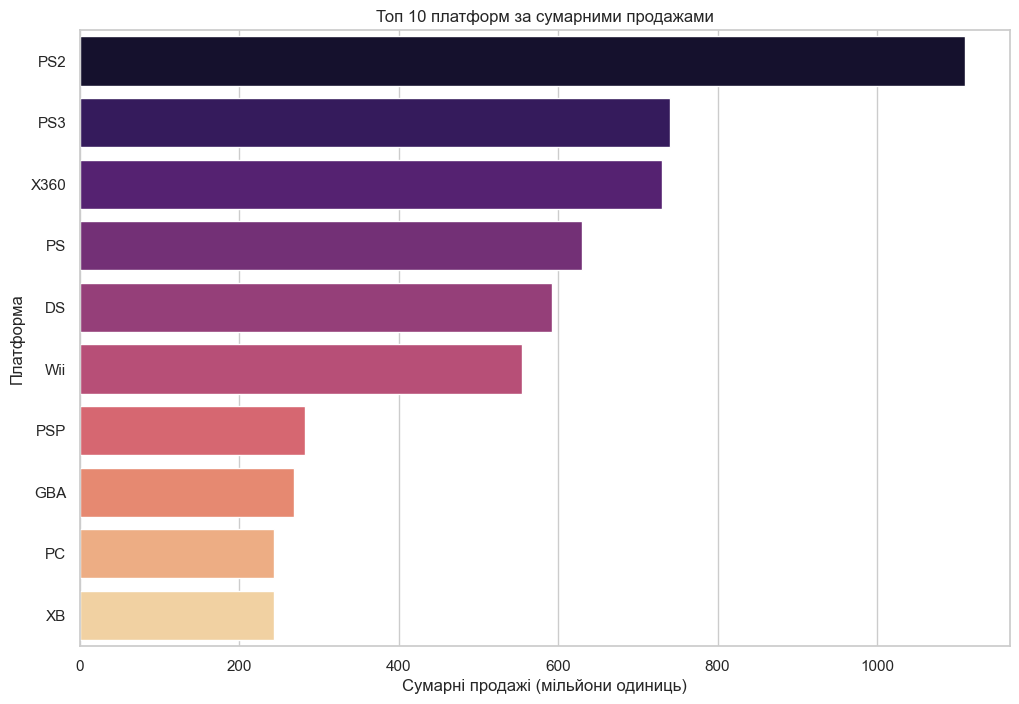

In [80]:
plt.figure(figsize=(12, 8))
sns.barplot(x='Global_Sales', y='Platform', data=top_platforms, palette='magma',hue='Platform')
plt.title('Топ 10 платформ за сумарними продажами')
plt.xlabel('Сумарні продажі (мільйони одиниць)')
plt.ylabel('Платформа')
plt.show()

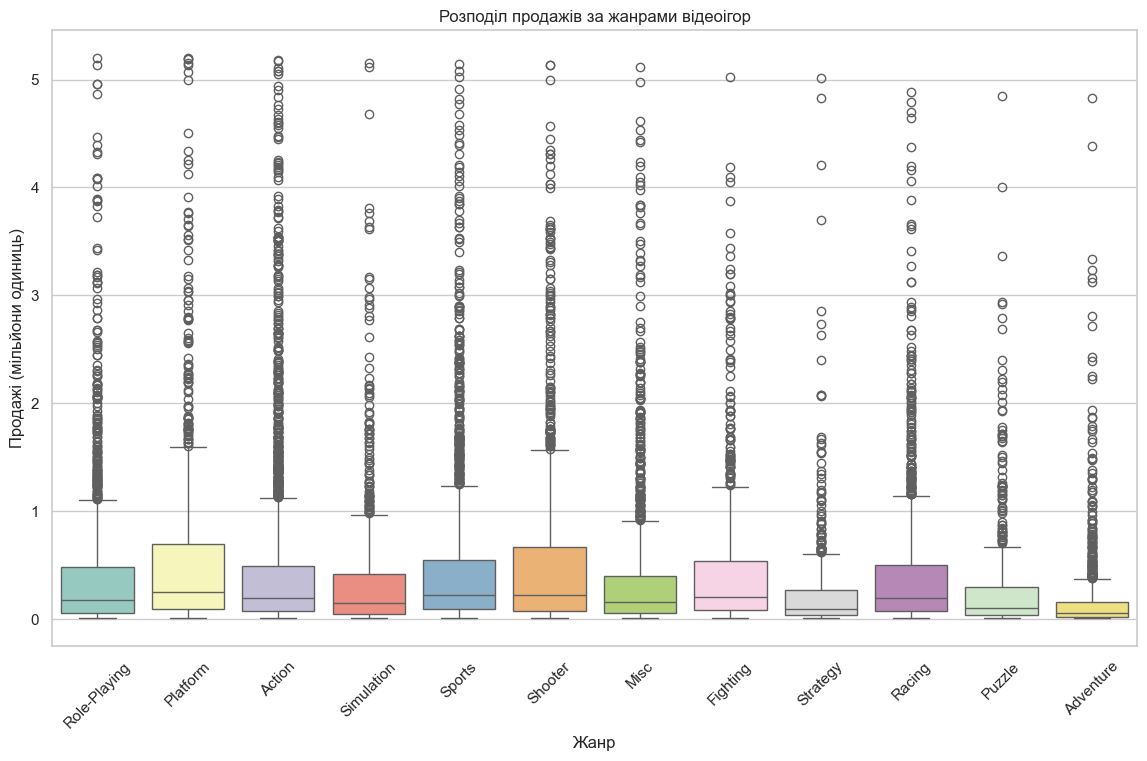

In [82]:
plt.figure(figsize=(14, 8))
sns.boxplot(x='Genre', y='Global_Sales', data=df, palette='Set3', hue='Genre')
plt.title('Розподіл продажів за жанрами відеоігор')
plt.xlabel('Жанр')
plt.ylabel('Продажі (мільйони одиниць)')
plt.xticks(rotation=45)
plt.show()

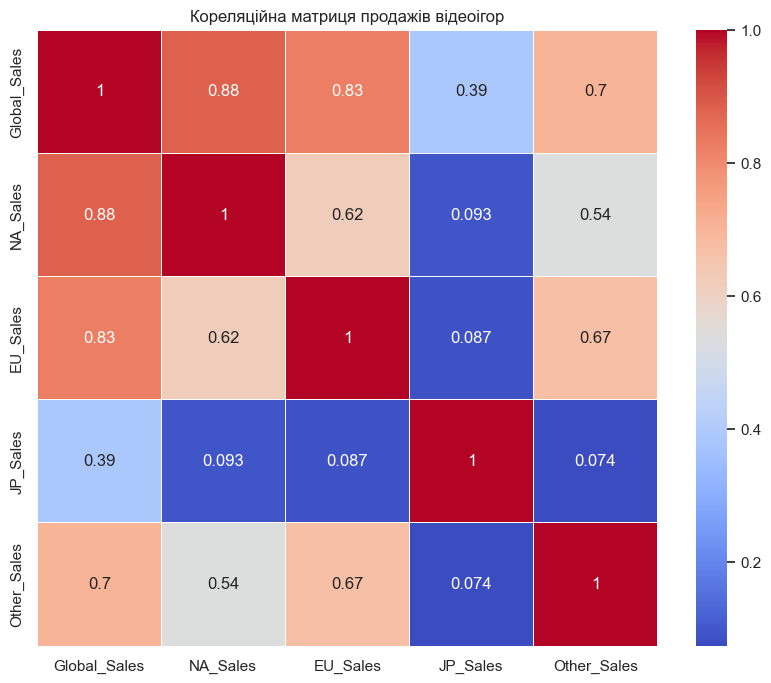

In [83]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', linewidths=0.5)
plt.title('Кореляційна матриця продажів відеоігор')
plt.show()

In [84]:
numerical_cols = ['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales', 'Global_Sales']

# Розрахунок кореляційної матриці
corr_matrix = df[numerical_cols].corr()

# Виведення кореляційної матриці
print("Кореляційна матриця:")
print(corr_matrix)

Кореляційна матриця:
              NA_Sales  EU_Sales  JP_Sales  Other_Sales  Global_Sales
NA_Sales      1.000000  0.619901  0.093079     0.536036      0.882119
EU_Sales      0.619901  1.000000  0.087134     0.667529      0.825695
JP_Sales      0.093079  0.087134  1.000000     0.073947      0.385867
Other_Sales   0.536036  0.667529  0.073947     1.000000      0.700921
Global_Sales  0.882119  0.825695  0.385867     0.700921      1.000000
